 Copyright © Sorbonne University.

 This source code is licensed under the MIT license found in the LICENSE file
 in the root directory of this source tree.

In [ ]:
**Authors:** Asmaa Jamai, Thomas Mattei
**GitHub repository:** https://github.com/asmaa-jamai/[REPO-NAME]

**AI use statement:** We used Claude (Anthropic) as a study assistant to understand the concepts, review our code and suggest improvements. We checked and understood all the code and comments.

# Outlook

In this notebook, we learn a forward model and a reward model 
of the MountainCarContinous environment using neural networks.
To evaluate the quality of the learned models, we perform trajectory 
optimization "in imagination" based on the model and determine whether
the obtained trajectories are good when played in the real environment 
instead of the model.

We first do all this naively then work on improving the general framework.

# Installation

In [42]:
import numpy as np
from typing import List, Tuple
import matplotlib
#matplotlib.use("QtAgg")
import matplotlib.pyplot as plt

import gymnasium as gym

from omegaconf import OmegaConf

import torch
import torch.nn as nn
from torch.nn import functional as func

# Hyper-parameters

In [43]:
rng = np.random.default_rng()

params = {
    "nb_episodes": 100,
    "nb_iter": 20,
    "elite_size": 15,
    "pop_size": 200,
    "sequence_len": 1000,
    "sigma": 0.8,
    "noise_multiplier": 0.99999,
    "indiv_repeat": 5,
    "learning_rate": 0.003,
    "train_set_size": 20000,
    }

In [44]:
def make_env(cfg):
    """
    Create the environment
    """
    mdp = gym.make(
        "MountainCarContinuous-v0" # "Pendulum-v1",
    )
    env = mdp.unwrapped  # the .unwrapped removes a warning from gymnasium when accessing an attribute or function
    return mdp, env

cfg=OmegaConf.create(params)
mdp, env = make_env(cfg)
mdp.reset()

(array([-0.5111503,  0.       ], dtype=float32), {})

Visualization of the results

In [45]:
def plot(curve, title):
        plt.plot(curve)

        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()


def plot_evo(scores, title):
        scores = np.array(scores)
        max_curve = scores.max(axis=1)
        mean_curve = scores.mean(axis=1)
        plt.plot(max_curve, color="red")
        plt.plot(mean_curve, color="blue")
        val_min = np.percentile(scores, 25, axis=1)
        val_max = np.percentile(scores, 75, axis=1)
        clipped = np.clip(scores, val_min[:, None], val_max[:, None])
        iqm = np.mean(clipped, axis=1)
        plt.plot(iqm, color="green")
        plt.fill_between(range(len(scores)), val_min, val_max, alpha=0.2, color="green")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

# Trajectory optimization

In this part we generate random action sequences, we evaluate them with a reward function
and we code the Cross-Entropy method to get trajectories of increasing value.

In the code below, write the standard reinforcement learning loop 
where the agent interacts with the environment until the episode 
terminates or is truncated.

In [46]:
def create_random_sequence(env, length):
  actions = [env.action_space.sample().item() for _ in range(length)]
  return actions

In [47]:
def evaluate_action_sequence_in_env(
    sequence: np.array,
) -> float:
    """
    Perform an episode on the given mdp given a sequence of actions
    :return: the cumulated reward
    """
    total_reward = 0
    _, _ = mdp.reset()
    terminated = False
    truncated = False
    step = 0

    while not (terminated or truncated) and step < len(sequence):
         action = np.array([sequence[step]])
         obs, reward, terminated, truncated, info = env.step(action)
         total_reward = total_reward + reward
         step += 1

    return total_reward

In [48]:
def evaluate_in_env(pop):
    scores = []
    for i in range(len(pop)):
        indiv_scores = []
        for _ in range(cfg.indiv_repeat):
            indiv_scores.append(evaluate_action_sequence_in_env(pop[i]))
            score = np.mean(indiv_scores)
        scores.append(score)
    return scores

## Real reward function of MountainCarContinuous

Find its definition on internet and fill the code

In [49]:
def reward_function(state, action):
    """
    Reward function for MountainCarContinuous.

    Parameters
    ----------
    position : float
        Car position after the transition.
    action : float or np.ndarray
        Action applied (typically in [-1, 1]).

    Returns
    -------
    float
        Reward for the transition.
    """
    position = state[0]
    velocity = state[1]
    a = float(np.squeeze(action))

    reward = -0.1 * a ** 2
    if position >= 0.45 and velocity >= 0:
        reward = reward + 100


    return reward

The full code for the cross-entropy method is given. Anyways, try to understand it, it is rather easy.

In [50]:
class CovMatrix:

    def __init__(self, centroid, sigma=0.1,
                 noise_multiplier=0.9,
                 diag_cov=True):

        self.diag_cov = diag_cov
        self.noise_multiplier = noise_multiplier
        n = len(centroid)
        self.noise = np.diag(np.ones(n) * sigma)

        self.cov = np.diag(np.ones(n) * np.var(centroid)) + self.noise

    def update_noise(self):
        self.noise = [
            x * self.noise_multiplier
            for x in self.noise
        ]

    def generate_pop(self, centroid, pop_size):
        return rng.multivariate_normal(centroid, self.cov, pop_size)

    def update_covariance(self, elite):
        self.cov = np.cov(np.transpose(elite)) + self.noise
        self.cov += 1e-6 * np.eye(self.cov.shape[0])

In [51]:
class CEM:

    def __init__(self, mu_init, elites_nb, **kwargs):

        self.centroid = mu_init
        self.elites_nb = elites_nb
        self.cov_matrix = CovMatrix(
            mu_init,
            **kwargs
        )

    def ask(self, pop_size):
        return self.cov_matrix.generate_pop(
            self.centroid,
            pop_size
        )

    def tell(self, params, fitness):

        # indices of best individuals
        elite_indices = sorted(
            range(len(fitness)),
            key=lambda i: fitness[i]
        )[-self.elites_nb:]

        elite = [
            params[i]
            for i in elite_indices
        ]

        # update centroid
        n = len(elite[0])

        self.centroid = [
            sum(w[j] for w in elite) / len(elite)
            for j in range(n)
        ]

        self.cov_matrix.update_noise()
        self.cov_matrix.update_covariance(elite)

## Performance of the CEM in the real environment

Write the main loop to try the above code

In [89]:
def cem_in_env():
    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    all_scores = []
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size), -1, 1)
        scores = evaluate_in_env(pop)
        cem.tell(pop, scores)
        all_scores.append(scores)

    plot_evo(all_scores, "CEM in env")
    return cem.centroid

# Learning forward dynamics and reward models with neural networks

The function below builds a multi-layer perceptron where the size of each
layer is given in the `size` list. We also specify the activation function of
neurons at each layer and optionally a different activation function for the
final layer.

All the code for representing and training neural networks is provided, but read it to understand it.
You need to fill the code of ```evaluate()``` function. 
It evaluates all individuals from the population by taking the average over cfg.indiv_repeat runs.
The parameter ```learned_reward``` tells whether we want to evaluate with the real reward function 
or the learned model of this function.

In [90]:
def build_mlp(sizes, activation, output_activation=nn.Identity()):
    """Helper function to build a multi-layer perceptron (function from $\mathbb R^n$ to $\mathbb R^p$)
    
    Args:
        sizes (List[int]): the number of neurons at each layer
        activation (nn.Module): a PyTorch activation function (after each layer but the last)
        output_activation (nn.Module): a PyTorch activation function for the last layer
    """
    layers = []
    for j in range(len(sizes) - 1):
        act = activation if j < len(sizes) - 2 else output_activation
        layers += [nn.Linear(sizes[j], sizes[j + 1]), act]
    return nn.Sequential(*layers)

In [91]:
class NeuralNetwork():
    def __init__(self, sizes, activation, output_activation):
        self.model = build_mlp(sizes, activation, output_activation)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=cfg.learning_rate)

    def train(self, input, output):
        x = self.forward(input).squeeze()
        loss = func.mse_loss(torch.Tensor(np.array(output)),x)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return loss.detach().numpy()

    def forward(self, input):
        x = torch.Tensor(np.array(input))
        return self.model.forward(x)

In [92]:
class Model():
    def __init__(self, sizes, activation, output_activation):
        self.forward_model = NeuralNetwork(sizes + [2], activation, output_activation)
        self.reward_model = NeuralNetwork(sizes + [1], activation, output_activation)

    def train_models(self):
        forward_losses = []
        reward_losses = []
        for i in range(cfg.train_set_size):
            action_sequence = create_random_sequence(env, cfg.sequence_len)
            states, actions, rewards, delta_states = collect_transition_and_reward_in_env(action_sequence)
            input = [np.concatenate((x, [y])) for x, y in zip(states, actions)]
            forward_loss = self.forward_model.train(input, delta_states)
            reward_loss = self.reward_model.train(input, rewards)
            forward_losses.append(forward_loss)
            reward_losses.append(reward_loss)
        # plot(forward_losses, "forward loss")
        # plot(reward_losses, "reward loss")

       
    def evaluate_one_action_sequence(self,
        sequence: np.array, learned_reward
    ) -> int:
        """
        Perform an episode in imagination given a sequence of actions
        :return: the cumulated reward
        """
        total_reward = 0
        state, _ = mdp.reset()
        steps = 0
        max_steps = mdp.spec.max_episode_steps
        terminated = False

        while not terminated and steps < len(sequence) and steps < max_steps:
            action = sequence[steps]
            input = np.concatenate((state, [action]))

            with torch.no_grad():
                delta = self.forward_model.forward(input).numpy()
            next_state = state + delta

            if learned_reward:
                with torch.no_grad():
                    reward = self.reward_model.forward(input).item()
            else:
                reward = reward_function(next_state, action)

            total_reward += reward
            terminated = next_state[0] >= 0.45 and next_state[1] >= 0
            state = next_state
            steps += 1

        
        return total_reward

    def evaluate(self, pop, learned_reward=True):
        scores = []
        
        for indiv in pop:
            indiv_scores = [
                self.evaluate_one_action_sequence(indiv, learned_reward)
                for _ in range(cfg.indiv_repeat)
            ]
            scores.append(np.mean(indiv_scores))
        return scores

        

In [93]:
def collect_transition_and_reward_in_env(
    sequence: np.array,
) -> Tuple[List, List, List, List]:
    """
    Perform an episode on the given mdp given a sequence of actions
    :return: the cumulated reward
    """
    states = []
    actions = []
    rewards = []
    delta_states = []
    state, _ = mdp.reset()
    terminated = False
    truncated = False
    steps = 0

    while not (terminated or truncated) and steps < len(sequence):
        action = sequence[steps]
        next_state, reward, terminated, truncated, info = env.step(np.array([action]))
        states.append(state)
        actions.append(action)
        rewards.append(reward)
        delta_states.append(next_state - state)
        state = next_state
        steps += 1

   
    return states, actions, rewards, delta_states

## Performance of the CEM trained with learned models

In the code below, we first learn a forward model and a reward model, then we apply
the CEM "in imagination" using the learned models, and we evaluate the performance
of the best trajectory found in the real environment.

In [94]:
def cem_in_full_model():
    
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())
    model.train_models()

    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    all_scores = []
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size), -1, 1)
        scores = model.evaluate(pop, learned_reward=True)
        cem.tell(pop, scores)
        all_scores.append(scores)

    plot_evo(all_scores, "CEM in full model")
    print("score in real env:", evaluate_action_sequence_in_env(cem.centroid))

In [95]:
cfg.train_set_size = 200
cfg.pop_size = 30
cfg.nb_iter = 5
cfg.indiv_repeat = 1

In [96]:
def cem_in_forward_model():
    
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())
    model.train_models()
    
    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    all_scores = []
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size),-1,1)
        scores = model.evaluate(pop, learned_reward=False)
        cem.tell(pop, scores)
        all_scores.append(scores)

    plot_evo(all_scores, "CEM in forward model")
    print("score in real env:", evaluate_action_sequence_in_env(cem.centroid))




## The line to run what you want to try

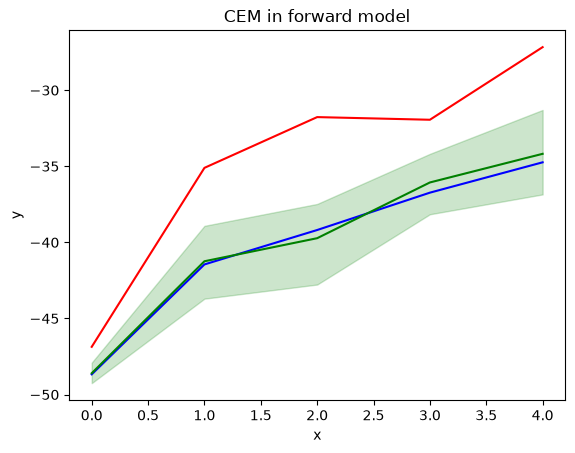

score in real env: -16.742495850842463


In [97]:
cem_in_forward_model()

## COMMENT: ##
planning in a forward model trained on random sequences does not work. The model is too optimistic: it imagines that the car 
reaches the flag, while in the real environment the score stays negative. (In a previous run, the full model with learned 
reward was even worse, because the reward network never sees the +100.

# Improvements

If you just followed instructions so far, you should have found that the naive approach
does not work.

There are several reasons why this fails:
- The models are trained from random sequences of actions. In MountainCarContinuous, 
with such random actions the car will most likely stay in the valley between hills: 
it does not learn much of the dynamics outside the valley. Training models with better 
sequences of actions (for instance those provided by the CEM) would improve that.
- Same point about the reward function: getting on the top of the hill is necessary 
to get the large positive reward. This (almost) never happens with random sequences of actions, 
hence the neural network cannot learn a proper reward model.
- The neural network is trained from data arriving sequentially. 
Such data is highly correlated. Using a dataloader would facilitate shuffling the data 
to prevent these correlations.
- Playing a long trajectory in imagination suffers from a coumpounding error issue: 
even if the models are making very small mistakes, these errors accumulate and 
the imagined trajectory ends up visiting states that are very different from 
the one it would visit in the real environment.

Now your goal is to turn the above code into something that works. We suggest the following changes:
- replace the model of the reward function by the true reward function and see if this works
- use a dataloader, shuffle the data and consider a validation loss when training the models
- create a dataset of successful trajectories using the CEM rather than using random trajectories
- learn a more sophisticated model of the reward function combining the goal-related reward (0, +100) 
and the action penalty reward.
- better tune all hyper-parameters, ask suggestions to your favorite generative AI.

Try as much as the above elements as you can and present your findings 
in a separate pdf document with figures.

In [87]:
def collect_cem_sequences():
    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    sequences = []
    all_scores = []
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size), -1, 1)
        scores = evaluate_in_env(pop)
        cem.tell(pop, scores)
        sequences.extend(pop)
        all_scores.append(scores)

    plot_evo(all_scores, "CEM in env (data collection)")
    return sequences


def train_on_sequences(model, sequences, n_epochs):
    for epoch in range(n_epochs):
        order = rng.permutation(len(sequences))
        for k in order:
            states, actions, rewards, delta_states = collect_transition_and_reward_in_env(sequences[k])
            input = [np.concatenate((x, [y])) for x, y in zip(states, actions)]
            model.forward_model.train(input, delta_states)
            model.reward_model.train(input, rewards)


def cem_in_forward_model_improved():
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())

    good = collect_cem_sequences()
    rand = [create_random_sequence(env, cfg.sequence_len) for _ in range(100)]
    train_on_sequences(model, good + rand, n_epochs=5)

    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    all_scores = []
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size), -1, 1)
        scores = model.evaluate(pop, learned_reward=False)
        cem.tell(pop, scores)
        all_scores.append(scores)

    plot_evo(all_scores, "CEM in forward model (CEM data)")
    print("score in real env:", evaluate_action_sequence_in_env(cem.centroid))

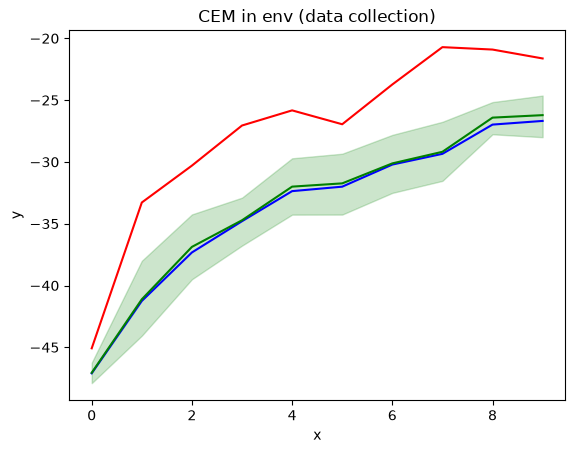

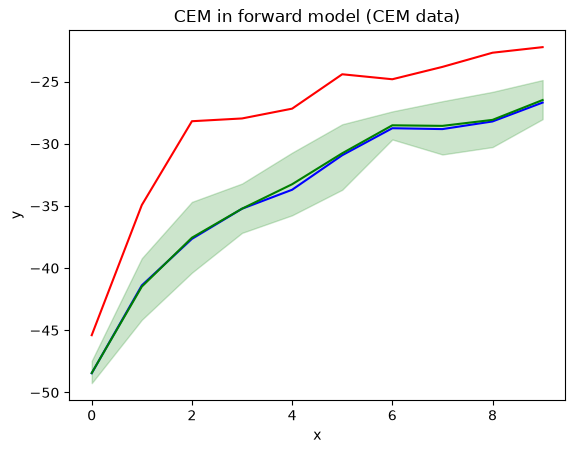

score in real env: -16.455214894519457


In [88]:
cfg.pop_size = 50
cfg.nb_iter = 10
cfg.indiv_repeat = 1
cfg.sigma = 0.1
cfg.noise_multiplier = 0.9
cem_in_forward_model_improved()

## Improvement 1: Dataset from CEM trajectories ##

The models are trained on the sequences tried by a CEM in the real environment (+100 random sequences) instead of only random ones, with clipped actions and sigma = 0.1. Why: with random actions the car stays in the valley, so the model never learns the dynamics on the hills. Result: the imagined and real curves are now very similar (from ≈-47 to ≈-25) and the real score (≈-16) is close to the imagined one: the model is realistic. But the car never reaches the flag: with a small sigma the CEM only learns to push less and never finds the +100.



**COMMENT**

Before moving to the other suggested improvements, we decided to modify some parameters of the CEM. The CEM in the real environment, which we use to collect the data, was getting worse at each iteration instead of improving. This happened because the generated actions were not limited to the action space: the environment clips them for the dynamics but still penalizes the original value, so large actions only add penalty. Moreover, with sigma = 0.8 and noise_multiplier = 0.99999 the noise added to the covariance almost never decreases, so the population becomes more and more spread and the CEM cannot converge. For this reason we clipped the actions to [-1, 1] in all the CEM loops and reduced sigma to 0.1 and noise_multiplier to 0.9. With these changes the CEM converges, both in the real environment and in the model, but with such a small sigma it explores too little and never reaches the flag: it only learns to push less. 

In [98]:
from torch.utils.data import TensorDataset, DataLoader

def build_dataset(sequences):
    X, Y_delta, Y_rew = [], [], []
    for seq in sequences:
        states, actions, rewards, delta_states = collect_transition_and_reward_in_env(seq)
        for s, a, r, d in zip(states, actions, rewards, delta_states):
            X.append(np.concatenate((s, [a])))
            Y_delta.append(d)
            Y_rew.append(r)
    return np.array(X, dtype=np.float32), np.array(Y_delta, dtype=np.float32), np.array(Y_rew, dtype=np.float32)


def train_with_dataloader(model, sequences, n_epochs=10, batch_size=256):
    X, Yd, Yr = build_dataset(sequences)

    idx = rng.permutation(len(X))
    n_val = len(X) // 5
    val, tr = idx[:n_val], idx[n_val:]

    loader = DataLoader(TensorDataset(torch.tensor(X[tr]), torch.tensor(Yd[tr]), torch.tensor(Yr[tr])),
                        batch_size=batch_size, shuffle=True, drop_last=True)

    train_losses, val_losses = [], []
    for epoch in range(n_epochs):
        for x, yd, yr in loader:
            model.forward_model.train(x.numpy(), yd.numpy())
            model.reward_model.train(x.numpy(), yr.numpy())

        with torch.no_grad():
            tr_loss = func.mse_loss(model.forward_model.forward(X[tr]), torch.tensor(Yd[tr])).item()
            val_loss = func.mse_loss(model.forward_model.forward(X[val]), torch.tensor(Yd[val])).item()
        train_losses.append(tr_loss)
        val_losses.append(val_loss)

    plt.plot(train_losses, label="train")
    plt.plot(val_losses, label="validation")
    plt.yscale("log")
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.title("Forward model loss")
    plt.legend()
    plt.show()


def cem_in_forward_model_dataloader():
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())

    good = collect_cem_sequences()
    rand = [create_random_sequence(env, cfg.sequence_len) for _ in range(100)]
    train_with_dataloader(model, good + rand, n_epochs=10)

    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    all_scores = []
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size), -1, 1)
        scores = model.evaluate(pop, learned_reward=False)
        cem.tell(pop, scores)
        all_scores.append(scores)

    plot_evo(all_scores, "CEM in forward model (dataloader)")
    print("score in real env:", evaluate_action_sequence_in_env(cem.centroid))

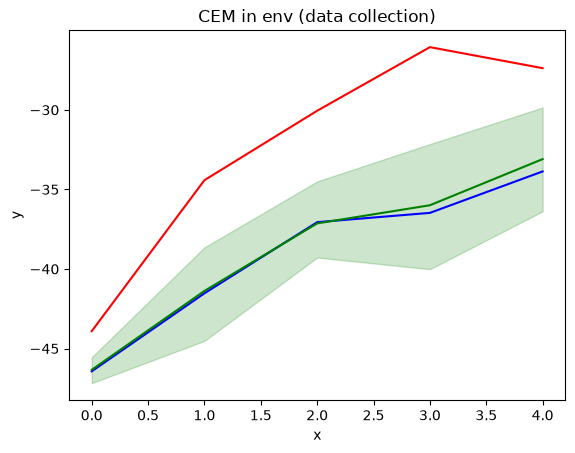

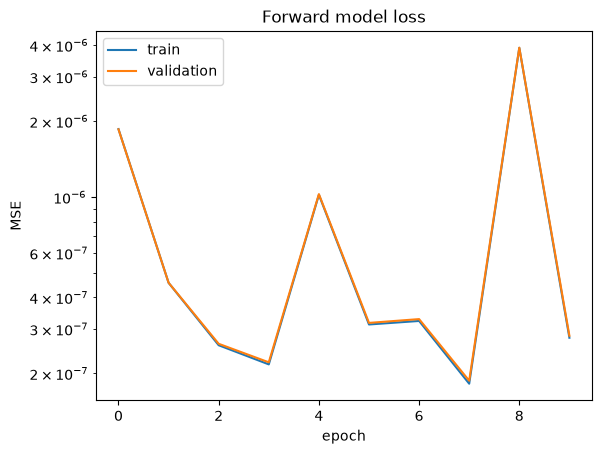

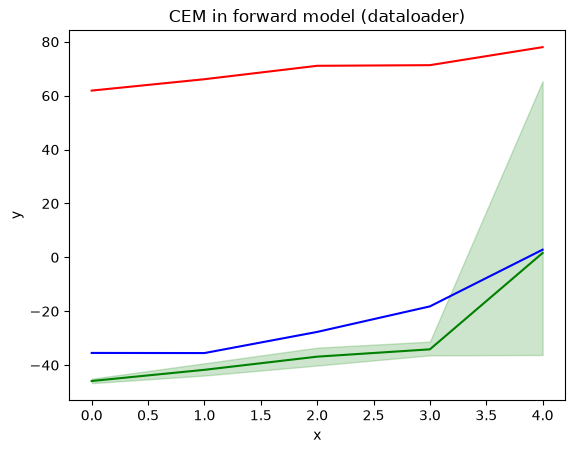

score in real env: -15.996874909717068


In [99]:
cem_in_forward_model_dataloader()

## IMPROVEMENT 2: Dataloader, shuffle, validation ##
Consecutive steps of an episode are very similar, so we shuffle all the steps of all the episodes to give the network more varied data, and we keep 20% of them to check that it does not overfit.
Results: train and validation losses are almost equal (no overfitting) and the one-step error is very small, with some peaks (learning rate a bit high). The real score does not change (~-16): the limit is the data, not the training.

In [103]:
class GoalModel():
    def __init__(self):
        self.model = build_mlp([3, 10, 10, 1], nn.Tanh(), nn.Identity())
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=cfg.learning_rate)

    def train(self, x, y, pos_weight):
        logits = self.model(x).squeeze(-1)
        loss = func.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

    def prob(self, input):
        with torch.no_grad():
            x = torch.tensor(np.array(input), dtype=torch.float32)
            return torch.sigmoid(self.model(x)).item()


def evaluate_sophisticated(model, goal_model, pop):
    scores = []
    for seq in pop:
        state, _ = mdp.reset()
        total_reward = 0
        for action in seq[:999]:
            input = np.concatenate((state, [action]))
            with torch.no_grad():
                delta = model.forward_model.forward(input).numpy()
            total_reward += -0.1 * action ** 2
            if goal_model.prob(input) > 0.5:
                total_reward += 100
                break
            state = state + delta
        scores.append(total_reward)
    return scores


def cem_in_full_model_sophisticated():
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())
    goal_model = GoalModel()

    good = collect_cem_sequences()
    rand = [create_random_sequence(env, cfg.sequence_len) for _ in range(100)]
    X, Yd, Yr = build_dataset(good + rand)
    Yg = (Yr > 50).astype(np.float32)

    n_pos = Yg.sum()
    print("transitions that reach the goal:", int(n_pos), "out of", len(Yg))
    pos_weight = torch.tensor(min((len(Yg) - n_pos) / max(n_pos, 1), 100.0))

    loader = DataLoader(TensorDataset(torch.tensor(X), torch.tensor(Yd), torch.tensor(Yg)),
                        batch_size=256, shuffle=True, drop_last=True)
    for epoch in range(10):
        for x, yd, yg in loader:
            model.forward_model.train(x.numpy(), yd.numpy())
            goal_model.train(x, yg, pos_weight)

    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    all_scores = []
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size), -1, 1)
        scores = evaluate_sophisticated(model, goal_model, pop)
        cem.tell(pop, scores)
        all_scores.append(scores)

    plot_evo(all_scores, "CEM in full model (sophisticated reward)")
    print("score in real env:", evaluate_action_sequence_in_env(cem.centroid))

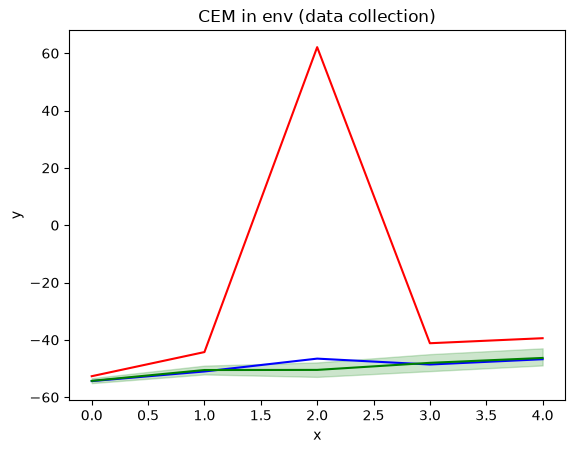

transitions that reach the goal: 1 out of 249823


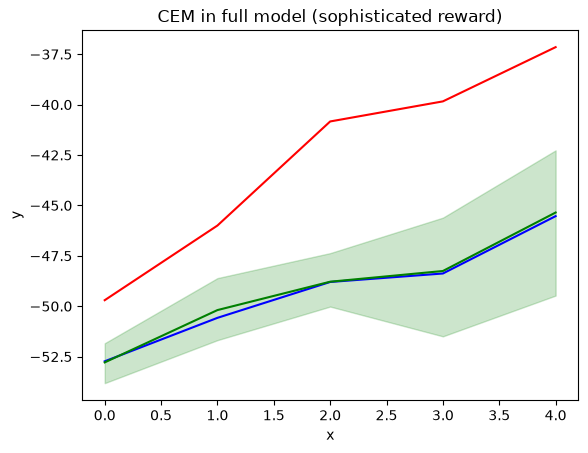

score in real env: -7.33256858499148


In [104]:
cem_in_full_model_sophisticated()

## Improvement 3: structured reward model ##
The reward has two very different parts, a tiny penalty at each step and a rare +100 when the car reaches the flag, so one network cannot learn both. We compute the penalty -0.1·a² exactly and train a classifier only to predict if the goal is reached; the +100 is counted only once and the imagined episode ends when P(goal) > 0.5. We limited pos_weight to 100 because in a first version, with only 3 goal examples, the classifier predicted the goal almost everywhere and the imagined scores went up to ~8000.

The first run uses sigma = 0.1 (the value from the previous tuning); in the next runs we tried sigma = 0.4 and 0.8 to make the CEM explore more and collect more trajectories that reach the flag, so that the classifier has more goal examples to learn from.

Result with sigma = 0.1: only 1 goal transition is collected, so the classifier never predicts the goal. The CEM in the model only learns to reduce the penalty (from ~-52 to ~-37) and the real score is ~-7: the car does not reach the flag.

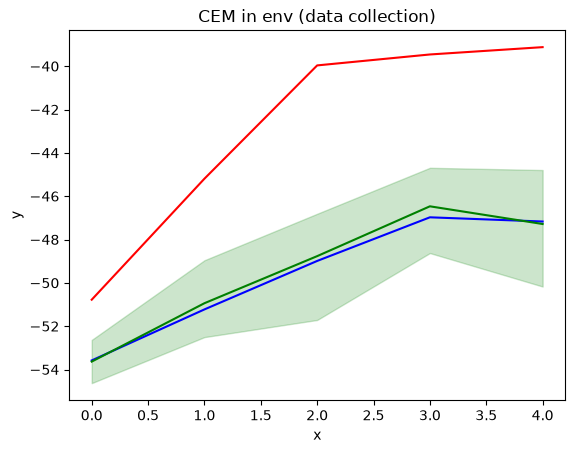

transitions that reach the goal: 1 out of 249521


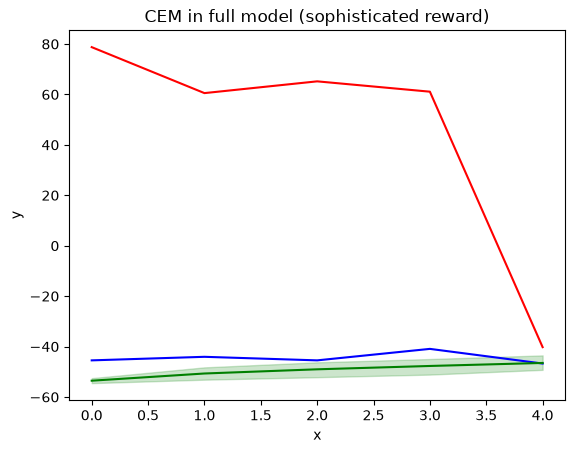

score in real env: -8.016885600269832


In [105]:
cfg.sigma = 0.4
cfg.noise_multiplier = 0.95
cem_in_full_model_sophisticated()

## Results with sigma = 0.4: ##
still 1 goal transition. The classifier gives some false goals (imagined max ~+60/+80 in the first iterations), but the population does not improve and the real score is ~-8.

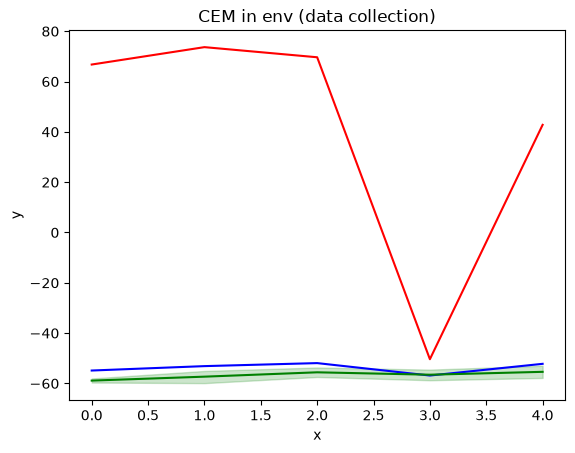

transitions that reach the goal: 9 out of 247930


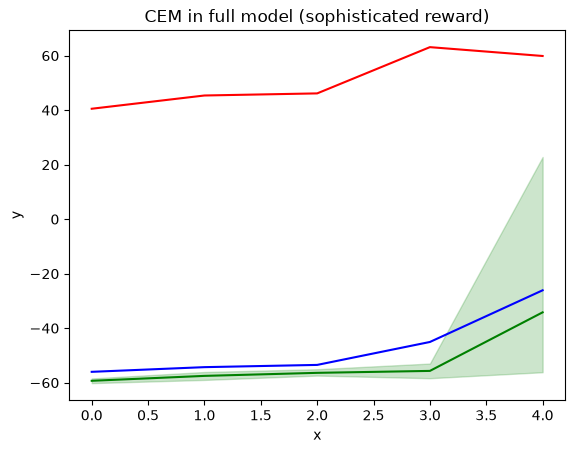

score in real env: -7.4323258404329335


In [106]:
cfg.sigma = 0.8
cfg.noise_multiplier = 0.95
cem_in_full_model_sophisticated()

## Results with sigma = 0.8: ##
the CEM explores more and collects 9 goal transitions. The CEM in the model improves (mean from ~-56 to ~-26, max ~+60), but the real score is still ~-7. The reward is better structured, but it cannot be learned from so few successful examples: the main limitation is exploration.

In [107]:
def cem_in_full_model_sophisticated_best():
    model = Model([3, 10, 10, 10], nn.Tanh(), nn.Identity())
    goal_model = GoalModel()

    good = collect_cem_sequences()
    rand = [create_random_sequence(env, cfg.sequence_len) for _ in range(100)]
    X, Yd, Yr = build_dataset(good + rand)
    Yg = (Yr > 50).astype(np.float32)

    n_pos = Yg.sum()
    print("transitions that reach the goal:", int(n_pos), "out of", len(Yg))
    pos_weight = torch.tensor(min((len(Yg) - n_pos) / max(n_pos, 1), 100.0))

    loader = DataLoader(TensorDataset(torch.tensor(X), torch.tensor(Yd), torch.tensor(Yg)),
                        batch_size=256, shuffle=True, drop_last=True)
    for epoch in range(10):
        for x, yd, yg in loader:
            model.forward_model.train(x.numpy(), yd.numpy())
            goal_model.train(x, yg, pos_weight)

    mu_init = create_random_sequence(env, cfg.sequence_len)
    cem = CEM(mu_init, cfg.elite_size, sigma=cfg.sigma, noise_multiplier=cfg.noise_multiplier)

    all_scores = []
    best_score = -np.inf
    for i in range(cfg.nb_iter):
        pop = np.clip(cem.ask(cfg.pop_size), -1, 1)
        scores = evaluate_sophisticated(model, goal_model, pop)
        cem.tell(pop, scores)
        all_scores.append(scores)
        if max(scores) > best_score:
            best_score = max(scores)
            best_seq = pop[np.argmax(scores)]

    plot_evo(all_scores, "CEM in full model (sophisticated reward, best sequence)")
    print("imagined best:", best_score)
    print("real score of centroid:", evaluate_action_sequence_in_env(cem.centroid))
    print("real score of best sequence:", evaluate_action_sequence_in_env(best_seq))

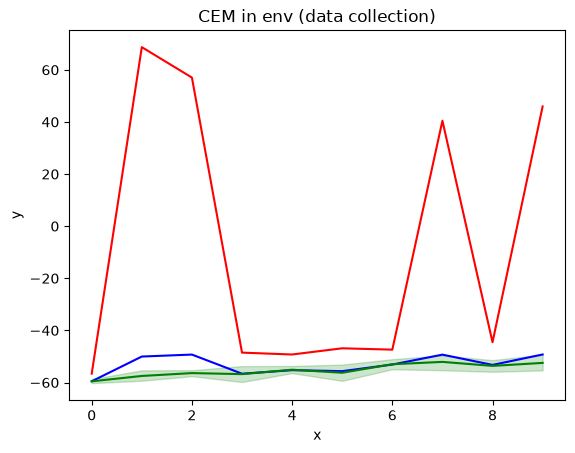

transitions that reach the goal: 4 out of 399328


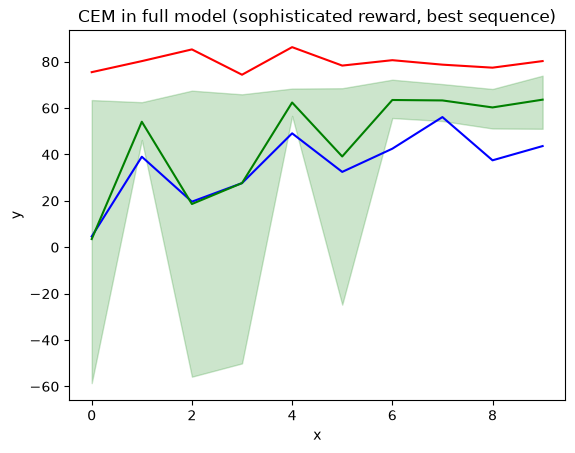

imagined best: 86.2787252124745
real score of centroid: -6.7201774515920265
real score of best sequence: -55.96478841031722


In [108]:
cfg.sigma = 0.8
cfg.noise_multiplier = 0.95
cfg.nb_iter = 10
cem_in_full_model_sophisticated_best()

## Improvement: we tried an extra one because the results does sill not reach the goal.

### test the best imagined sequence, not only the CEM centroid (10 iterations) ###

Why: The centroid is an average of the elites. Averaging could cancel the back-and-forth swing the car needs to climb.

Results: Imagined best is about +86, but in reality the same sequence gets about −56. The real centroid gets about −7, so neither of them reaches the goal. The problem is not the centroid: the CEM exploits the errors of the model. The goal classifier, trained on only 4 examples, gives false positives, and small errors in the dynamics model add up over many steps (compounding error). This is model exploitation.

## END OF THE FIRST SIMULATION: 
## We worked on two computers in parallel. On the first (UP) one we added one improvement at a time and looked at each result separately, to understand what every change contributed. On the second one (BELOW) we used our favourite LLM more “shamelessly”, to get the best possible results by combining all the improvements together.

In [109]:
from torch.utils.data import TensorDataset, DataLoader

POS_MIN, POS_MAX = -1.2, 0.6
VEL_MAX = 0.07
GOAL_POS = 0.45

# ---------- hyper-parameters of the improved pipeline ----------
P = OmegaConf.create(dict(
    collect_pop=50, collect_iter=6, collect_elite=10, collect_sigma=0.8,
    plan_pop=100, plan_iter=10, plan_elite=10, plan_sigma=0.3,
    n_rounds=2, n_starts=3,
    hidden=64, lr=1e-3, batch_size=256,
    init_epochs=15, round_epochs=3,
    n_random=30, val_ratio=0.2,
))


# ---------- data ----------
def episodes_to_arrays(episodes):
    X, D, G = [], [], []
    for states, actions, rewards, deltas in episodes:
        for s, a, r, d in zip(states, actions, rewards, deltas):
            X.append([s[0], s[1], a])
            D.append(d)
            G.append(1.0 if r > 50 else 0.0)
    return (np.array(X, dtype=np.float32), np.array(D, dtype=np.float32),
            np.array(G, dtype=np.float32))


def sequences_to_transitions(sequences):
    return episodes_to_arrays([collect_transition_and_reward_in_env(s) for s in sequences])


def real_score(seq, n=5):
    return np.mean([evaluate_action_sequence_in_env(seq) for _ in range(n)])


def run_cem_real():
    cem = CEM(create_random_sequence(env, cfg.sequence_len), P.collect_elite,
              sigma=P.collect_sigma, noise_multiplier=cfg.noise_multiplier)
    episodes, all_scores = [], []
    best_seq, best_score = None, -np.inf
    for it in range(P.collect_iter):
        print(f"collecting... iteration {it + 1}/{P.collect_iter}")
        pop = np.clip(cem.ask(P.collect_pop), -1, 1)
        played = [collect_transition_and_reward_in_env(s) for s in pop]
        scores = [sum(ep[2]) for ep in played]
        cem.tell(pop, scores)
        for i in np.argsort(scores)[-P.collect_elite:]:
            episodes.append(played[i])
        all_scores.append(scores)
        if max(scores) > best_score:
            best_score, best_seq = max(scores), pop[int(np.argmax(scores))]
    plot_evo(all_scores, "Real env CEM (data collection)")
    return episodes, best_seq


# ---------- model ----------
class ImprovedModel:
    def __init__(self, hidden, lr):
        self.dyn = build_mlp([3, hidden, hidden, 2], nn.Tanh())
        self.goal = build_mlp([3, hidden, hidden, 1], nn.Tanh())
        self.opt = torch.optim.Adam(list(self.dyn.parameters()) + list(self.goal.parameters()), lr=lr)

    def fit_normalization(self, X, D):
        self.x_mean, self.x_std = X.mean(0), X.std(0) + 1e-8
        self.d_mean, self.d_std = D.mean(0), D.std(0) + 1e-8

    def _nx(self, X):
        return torch.as_tensor((X - self.x_mean) / self.x_std, dtype=torch.float32)

    def _nd(self, D):
        return torch.as_tensor((D - self.d_mean) / self.d_std, dtype=torch.float32)

    def predict(self, X):
        with torch.no_grad():
            xn = self._nx(X)
            delta = self.dyn(xn).numpy() * self.d_std + self.d_mean
            p_goal = torch.sigmoid(self.goal(xn)).numpy().squeeze(-1)
        return delta, p_goal

    def dyn_loss(self, X, D):
        with torch.no_grad():
            return func.mse_loss(self.dyn(self._nx(X)), self._nd(D)).item()

    def train_epochs(self, X, D, G, Xv, Dv, n_epochs):
        loader = DataLoader(TensorDataset(self._nx(X), self._nd(D), torch.as_tensor(G)),
                            batch_size=P.batch_size, shuffle=True)
        n_pos = max(G.sum(), 1.0)
        bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([min((len(G) - n_pos) / n_pos, 1000.0)]))
        hist = []
        for ep in range(n_epochs):
            for xb, db, gb in loader:
                loss = func.mse_loss(self.dyn(xb), db) + bce(self.goal(xb).squeeze(-1), gb)
                self.opt.zero_grad()
                loss.backward()
                self.opt.step()
            hist.append((self.dyn_loss(X, D), self.dyn_loss(Xv, Dv)))
        return hist


# ---------- imagination and planning ----------
def imagine(model, pop, use_learned_reward, n_starts):
    pop = np.repeat(np.asarray(pop, dtype=np.float32), n_starts, axis=0)
    n = len(pop)
    states = np.array([mdp.reset()[0] for _ in range(n)], dtype=np.float32)
    total = np.zeros(n)
    done = np.zeros(n, dtype=bool)
    for t in range(min(pop.shape[1], mdp.spec.max_episode_steps)):
        a = pop[:, t]
        delta, p_goal = model.predict(np.column_stack([states, a]))
        nxt = states + delta
        nxt[:, 0] = np.clip(nxt[:, 0], POS_MIN, POS_MAX)
        nxt[:, 1] = np.clip(nxt[:, 1], -VEL_MAX, VEL_MAX)
        if use_learned_reward:
            r = -0.1 * a ** 2 + 100 * p_goal
            finished = p_goal > 0.5
        else:
            finished = (nxt[:, 0] >= GOAL_POS) & (nxt[:, 1] >= 0)
            r = -0.1 * a ** 2 + 100 * finished
        total += r * (~done)
        done |= finished
        states = nxt
        if done.all():
            break
    return total.reshape(-1, n_starts).mean(axis=1)


def plan(model, init_seq, use_learned_reward):
    cem = CEM(list(init_seq), P.plan_elite, sigma=P.plan_sigma, noise_multiplier=cfg.noise_multiplier)
    all_scores = []
    for it in range(P.plan_iter):
        pop = np.clip(cem.ask(P.plan_pop), -1, 1)
        scores = imagine(model, pop, use_learned_reward, P.n_starts)
        cem.tell(pop, scores)
        all_scores.append(scores)
    return pop, scores, np.clip(cem.centroid, -1, 1), all_scores


# ---------- full experiment ----------
def model_based_improved(use_learned_reward=False):
    label = "learned goal reward" if use_learned_reward else "true reward"

    good_eps, best_real_seq = run_cem_real()
    print("collecting random episodes...")
    rand_eps = [collect_transition_and_reward_in_env(create_random_sequence(env, cfg.sequence_len))
                for _ in range(P.n_random)]
    eps = good_eps + rand_eps
    idx = rng.permutation(len(eps))
    n_val = int(P.val_ratio * len(eps))
    Xv, Dv, Gv = episodes_to_arrays([eps[i] for i in idx[:n_val]])
    X, D, G = episodes_to_arrays([eps[i] for i in idx[n_val:]])
    print(f"Dataset: {len(X)} transitions ({int(G.sum())} at goal), validation: {len(Xv)}")

    baseline = real_score(best_real_seq)
    print(f"Baseline (best sequence of real CEM, 5 starts): {baseline:.2f}")

    print("training the model...")
    model = ImprovedModel(P.hidden, P.lr)
    model.fit_normalization(X, D)
    loss_hist = model.train_epochs(X, D, G, Xv, Dv, P.init_epochs)

    init_seq, best_found, best_found_score = best_real_seq, best_real_seq, baseline
    rounds = []
    for r in range(P.n_rounds):
        print(f"planning... round {r + 1}/{P.n_rounds}")
        pop, scores, centroid, all_scores = plan(model, init_seq, use_learned_reward)
        elite_idx = np.argsort(scores)[-P.plan_elite:]
        best = pop[elite_idx[-1]]
        rb, rc = real_score(best), real_score(centroid)
        rounds.append((max(scores), rb, rc))
        print(f"Round {r}: imagined best = {max(scores):.2f}   real best = {rb:.2f}   real centroid = {rc:.2f}")

        cand, cand_score = (best, rb) if rb >= rc else (centroid, rc)
        if cand_score > best_found_score:
            best_found, best_found_score, init_seq = cand, cand_score, cand

        if r < P.n_rounds - 1:
            print("retraining with the new data...")
            Xn, Dn, Gn = sequences_to_transitions(list(pop[elite_idx]) + [centroid])
            X, D, G = np.concatenate([X, Xn]), np.concatenate([D, Dn]), np.concatenate([G, Gn])
            loss_hist += model.train_epochs(X, D, G, Xv, Dv, P.round_epochs)

    plot_evo(all_scores, f"Planning in the model, last round ({label})")

    tr, va = zip(*loss_hist)
    plt.plot(tr, label="train"); plt.plot(va, label="validation")
    plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("normalized MSE")
    plt.title("Forward model loss"); plt.legend(); plt.show()

    im, rb_h, rc_h = zip(*rounds)
    plt.plot(im, "o-", label="imagined best"); plt.plot(rb_h, "o-", label="real best")
    plt.plot(rc_h, "o-", label="real centroid"); plt.axhline(baseline, ls="--", c="gray", label="baseline")
    plt.xlabel("round"); plt.ylabel("score"); plt.title(f"Imagination vs reality ({label})")
    plt.legend(); plt.show()

    reached = "REACHES the goal (on average)" if best_found_score > 0 else "does NOT reach the goal"
    print(f"FINAL ({label}): baseline = {baseline:.2f}   best found = {best_found_score:.2f}  -> {reached}")
    return best_found, best_found_score

collecting... iteration 1/6
collecting... iteration 2/6
collecting... iteration 3/6
collecting... iteration 4/6
collecting... iteration 5/6
collecting... iteration 6/6


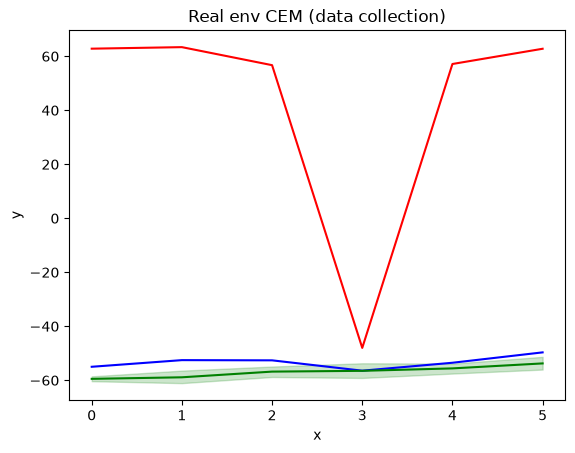

collecting random episodes...
Dataset: 70508 transitions (6 at goal), validation: 17161
Baseline (best sequence of real CEM, 5 starts): 63.29
training the model...
planning... round 1/2
Round 0: imagined best = -30.38   real best = -30.38   real centroid = -11.38
retraining with the new data...
planning... round 2/2
Round 1: imagined best = 80.38   real best = 13.39   real centroid = 91.66


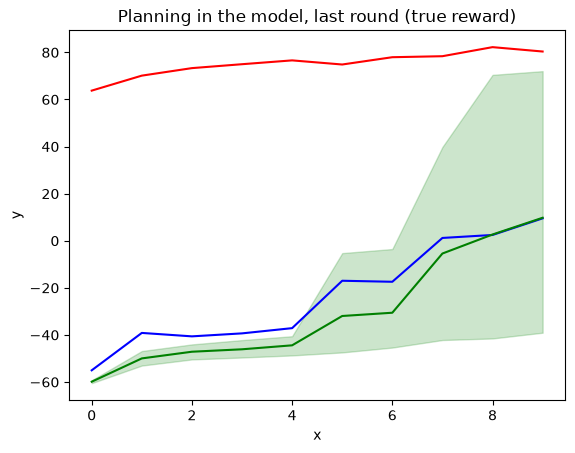

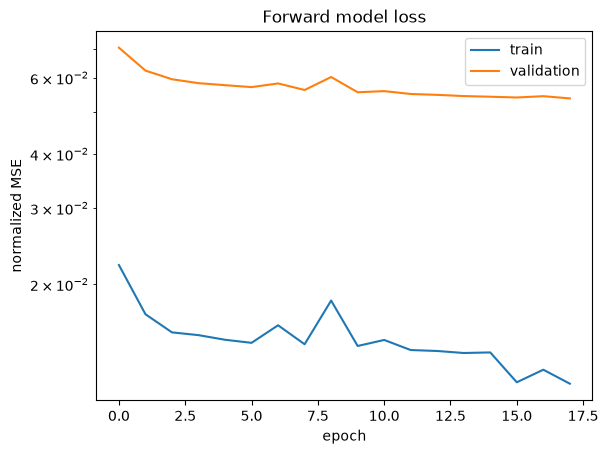

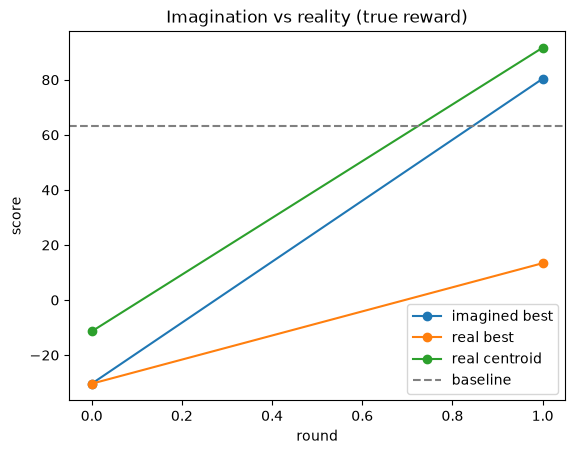

FINAL (true reward): baseline = 63.29   best found = 91.66  -> REACHES the goal (on average)


In [110]:
best_seq_true, score_true = model_based_improved(use_learned_reward=False)

collecting... iteration 1/6
collecting... iteration 2/6
collecting... iteration 3/6
collecting... iteration 4/6
collecting... iteration 5/6
collecting... iteration 6/6


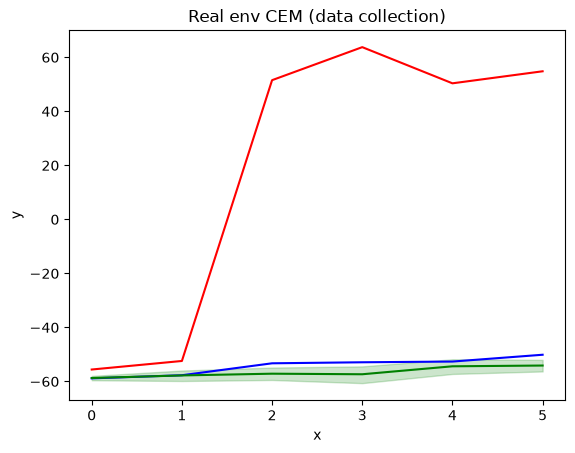

collecting random episodes...
Dataset: 71012 transitions (6 at goal), validation: 17972
Baseline (best sequence of real CEM, 5 starts): 63.75
training the model...
planning... round 1/2
Round 0: imagined best = 456.47   real best = -37.15   real centroid = 3.51
retraining with the new data...
planning... round 2/2
Round 1: imagined best = 382.89   real best = 45.75   real centroid = -13.21


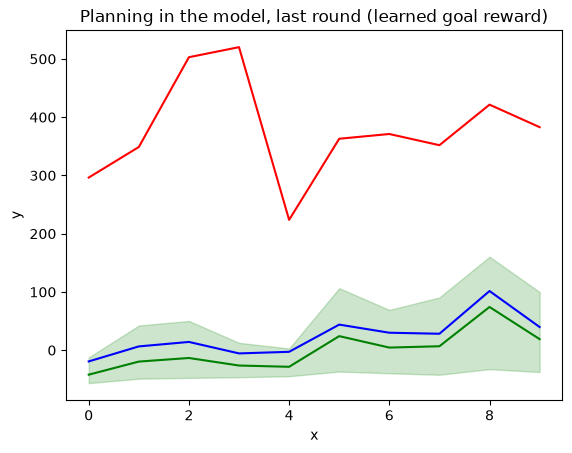

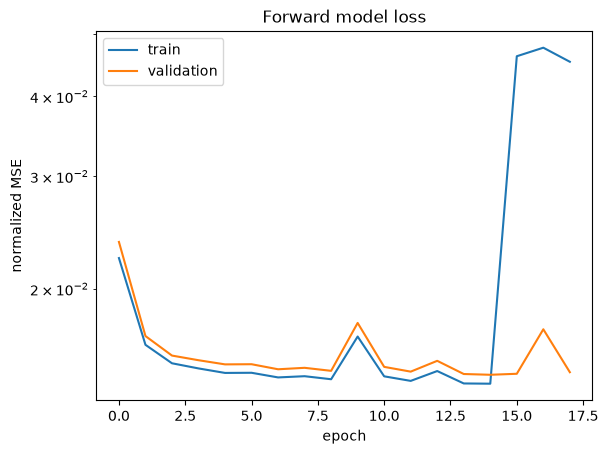

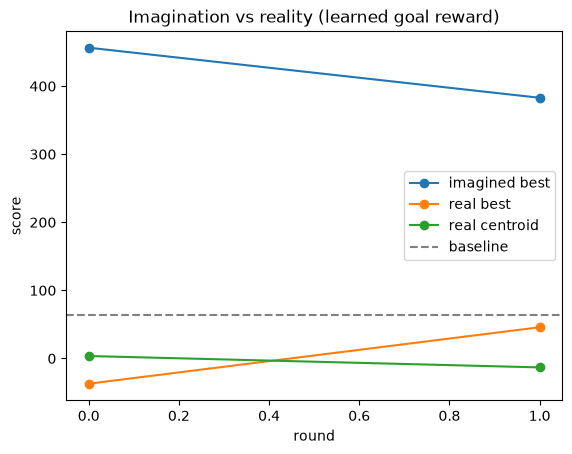

FINAL (learned goal reward): baseline = 63.75   best found = 63.75  -> REACHES the goal (on average)


In [111]:
best_seq_learned, score_learned = model_based_improved(use_learned_reward=True)


### RESULTS
True reward: the real CEM baseline is about +63. After one retraining round the plan found in the model reaches about +92 in reality: the car reaches the goal and the model improves the real solution. In the first round imagined and real scores were identical (about -30).

Learned goal classifier: the imagined scores reach about 400, while the real maximum is about +100, because 100·P(goal) is added at every step until the goal is predicted (we fixed the same problem in our structured reward model by counting the +100 only once). With only 6 goal examples the CEM exploits the classifier's mistakes: no plan beats the baseline, so the final result (about +64) is just the real CEM sequence.

Limits: single run with small parameters; all improvements are applied together, so we cannot measure each one separately; the warm start already begins from a sequence that sometimes reaches the goal.

# CONCLUSION
We compared three approaches:

**1. Naive approach (models trained on random actions)**
- The car stays in the valley, so the model never learns how to climb.
- With the true reward the model is too optimistic: it imagines reaching the flag, but in reality it does not.
- With the learned reward the network never sees the +100, so the CEM has nothing useful to optimize.
- Result: the car never reaches the flag.

**2. Step-by-step improvements (one change at a time)**
- CEM data: the model becomes realistic (imagined ≈ real scores).
- Clipping and sigma: the CEM converges, but a small sigma explores too little.
- Dataloader + validation: stable training, no overfitting, but the same real result.
- Structured reward: no more overestimation, but too few goal examples to learn from.
- Best sequence: the CEM exploits the errors of the model (imagined ~+86, real ~-56).
- Result: each change helps a bit, but the car still never reaches the flag.

**3. Final pipeline (all improvements together + retraining rounds)**
- With the true reward the car reaches the flag (~+92, better than the real CEM baseline ~+63).
- With the learned reward the model still overestimates (~400) and does not beat the baseline.
- Result: it works only with the true reward.

**What we learned**
- A model is only as good as its data: the car must actually reach the flag during exploration.
- The CEM always finds the errors of the model, so we must test the plans in reality and retrain the model with the new data.
- Learning a sparse reward (+100 very rarely) is the hardest part.